In [11]:
import os
import cv2
import json
import glob
import tiffslide
import numpy as np
import random
from shapely.geometry import shape, box, Polygon, MultiPolygon
from shapely.affinity import translate

# --- CONFIGURACIÓN ---data
RAW_DATA_DIR = os.path.join("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR,"data/processed/YOLO-1280x1280-256ovlp")
METADATA_DIR = os.path.join(RAW_DATA_DIR,"data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)


TILE_SIZE = 1280
OVERLAP = 256
TRAIN_RATIO = 0.8  # 80% entrenamiento, 20% validación
random.seed(42)


# Generación de tiles con categorias

In [7]:
images_excluded = ['slide_007', 'slide_008', 'slide_016', 'slide_018', 'slide_019', 'slide_025', 'slide_028', 'slide_029', 'slide_032', 'slide_034', 'slide_035', 'slide_041', 'slide_045', 'slide_047', 'slide_048']





CLASS_MAP = {
    "Decidua": 0, "Decidual": 0, "dec": 0, "dec1": 0, "dec2": 0,
    "Labyrinth": 1, "lab": 1, "lab1": 1, "lab2": 1,
    "Junctional Zone": 2, "jz": 2, "Junctional": 2
}

def get_yolo_segment_format(geometry, img_w, img_h):
    """Convierte geometría Shapely a string de puntos normalizados para YOLO-SEG."""
    results = []
    
    # Aseguramos que tratamos todo como una lista de geometrías
    if isinstance(geometry, Polygon):
        polys = [geometry]
    elif isinstance(geometry, MultiPolygon):
        polys = geometry.geoms
    else:
        # Si es una LineString o Point producto de la intersección, la ignoramos
        return results
    
    for poly in polys:
        # CORRECCIÓN AQUÍ: .is_empty (con punto y sin el 'inter' pegado)
        if poly.is_empty or not isinstance(poly, Polygon): 
            continue
            
        coords = np.array(poly.exterior.coords)
        
        # Normalizar (0 a 1)
        coords[:, 0] /= img_w
        coords[:, 1] /= img_h
        
        # YOLO necesita al menos 3 puntos para un polígono
        if len(coords) < 3: 
            continue
            
        # Aplanar y convertir a string
        flattened = coords.flatten().tolist()
        results.append(" ".join(map(str, flattened)))
        
    return results

# 1. Crear estructura de carpetas
for split in ['train', 'val']:
    os.makedirs(os.path.join(OUTPUT_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, "labels", split), exist_ok=True)

# 2. Split de archivos (por imagen completa)
image_files = sorted(glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif")))
# Excluir imágenes que no sirven para entrenamiento
image_files = [f for f in image_files if f.split('\\')[-1].replace('.tif','') not in images_excluded]
random.shuffle(image_files)
split_idx = int(len(image_files) * TRAIN_RATIO)
train_files = set(image_files[:split_idx])

print(f"📂 Total imágenes: {len(image_files)} | Train: {len(train_files)} | Val: {len(image_files)-len(train_files)}")

# 3. Bucle Principal
for img_path in image_files:
    base_name = os.path.basename(img_path).replace(".tif", "")
    geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
    current_split = "train" if img_path in train_files else "val"
    
    if not os.path.exists(geojson_path): continue

    print(f"🚜 Procesando {base_name} para {current_split}...")

    with tiffslide.TiffSlide(img_path) as slide:
        w, h = slide.dimensions
        full_img = np.array(slide.read_region((0,0), 0, (w, h)).convert("RGB"))
        full_img = cv2.cvtColor(full_img, cv2.COLOR_RGB2BGR)

    with open(geojson_path, 'r') as f:
        data = json.load(f)
        features = [
            {"geom": shape(f['geometry']), "class": f['properties'].get('name')}
            for f in data.get('features', [])
        ]

    count = 0
    for y in range(0, h - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
        for x in range(0, w - TILE_SIZE + 1, TILE_SIZE - OVERLAP):
            tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
            tile_labels = []

            for feat in features:
                if tile_box.intersects(feat['geom']):
                    inter = feat['geom'].intersection(tile_box)
                    
                    # Ignorar si la intersección no tiene área (puntos o líneas sueltas)
                    if inter.is_empty or inter.area < 100: continue
                    
                    # Mover polígono al origen del parche
                    local_poly = translate(inter, xoff=-x, yoff=-y)
                    class_id = CLASS_MAP.get(feat['class'], -1)
                    
                    if class_id != -1:
                        yolo_segs = get_yolo_segment_format(local_poly, TILE_SIZE, TILE_SIZE)
                        for seg in yolo_segs:
                            tile_labels.append(f"{class_id} {seg}")

            if tile_labels:
                tile_name = f"{base_name}_tile_{x}_{y}"
                img_out = os.path.join(OUTPUT_DIR, "images", current_split, f"{tile_name}.jpg")
                lbl_out = os.path.join(OUTPUT_DIR, "labels", current_split, f"{tile_name}.txt")
                
                cv2.imwrite(img_out, full_img[y:y+TILE_SIZE, x:x+TILE_SIZE])
                with open(lbl_out, 'w') as f:
                    f.write("\n".join(tile_labels))
                count += 1

    print(f"✅ {base_name}: {count} parches creados.")

# 4. Crear archivo dataset.yaml
yaml_content = f"""
path: {os.path.abspath(OUTPUT_DIR)}
train: images/train
val: images/val

names:
  0: Decidua
  1: Labyrinth
  2: Junctional Zone
"""
with open(os.path.join(OUTPUT_DIR, "dataset.yaml"), "w") as f:
    f.write(yaml_content)

print(f"\n🚀 Proceso terminado. Dataset listo en: {OUTPUT_DIR}")

📂 Total imágenes: 65 | Train: 52 | Val: 13
🚜 Procesando slide_003 para train...
✅ slide_003: 26 parches creados.
🚜 Procesando slide_065 para train...
✅ slide_065: 61 parches creados.
🚜 Procesando slide_013 para train...
✅ slide_013: 21 parches creados.
🚜 Procesando slide_063 para train...
✅ slide_063: 61 parches creados.
🚜 Procesando slide_009 para train...
✅ slide_009: 29 parches creados.
🚜 Procesando slide_037 para train...
✅ slide_037: 26 parches creados.
🚜 Procesando slide_023 para train...
✅ slide_023: 33 parches creados.
🚜 Procesando slide_029 para train...
✅ slide_029: 29 parches creados.
🚜 Procesando slide_055 para train...
✅ slide_055: 69 parches creados.
🚜 Procesando slide_014 para train...
✅ slide_014: 16 parches creados.
🚜 Procesando slide_002 para train...
✅ slide_002: 30 parches creados.
🚜 Procesando slide_016 para train...
✅ slide_016: 30 parches creados.
🚜 Procesando slide_040 para train...
✅ slide_040: 26 parches creados.
🚜 Procesando slide_054 para train...
✅ slide_05

# Generación de tiles de fondos_

In [8]:
import os
import glob
import json
import random
import cv2
import numpy as np
import tiffslide
from shapely.geometry import shape, box
from shapely.ops import unary_union

# --- CONFIGURACIÓN ---
RAW_DATA_DIR = os.path.join("/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026")
WSI_IMAGES_DIR = os.path.join(RAW_DATA_DIR, "data/raw/wsi_images")
ANNOTATIONS_DIR = os.path.join(RAW_DATA_DIR, "data/raw/annotations_resized")
OUTPUT_DIR = os.path.join(RAW_DATA_DIR,"data/processed/YOLO-1280x1280-256ovlp_w_bgs")
METADATA_DIR = os.path.join(RAW_DATA_DIR,"data/raw/metadata")
os.makedirs(OUTPUT_DIR, exist_ok=True)
t = "train" # O "val", depende dónde quieras más fondos
v = 'val'
TILE_SIZE = 1280
NUM_BACKGROUND_TILES_PER_IMAGE = 5 # Cuántos fondos quieres por imagen grande

# 1. Crear carpetas si no existen
os.makedirs(os.path.join(OUTPUT_DIR, "images", t), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "labels", t), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "images", v), exist_ok=True)
os.makedirs(os.path.join(OUTPUT_DIR, "labels", v), exist_ok=True)
image_files = glob.glob(os.path.join(WSI_IMAGES_DIR, "*.tif"))

for img_path in image_files:
    base_name = os.path.basename(img_path).replace(".tif", "")
    geojson_path = os.path.join(ANNOTATIONS_DIR, f"{base_name}.geojson")
    
    if not os.path.exists(geojson_path): continue
    
    print(f"🔍 Buscando fondos en {base_name}...")
    
    with tiffslide.TiffSlide(img_path) as slide:
        w, h = slide.dimensions
        
        # Cargar anotaciones para saber dónde NO hay tejido
        with open(geojson_path, 'r') as f:
            data = json.load(f)
            features = [shape(f['geometry']) for f in data.get('features', [])]
            
        if not features: continue
        all_labels_geom = unary_union(features)
        
        # 2. Bucle para generar fondos
        generated_backgrounds = 0
        attempts = 0
        
        while generated_backgrounds < NUM_BACKGROUND_TILES_PER_IMAGE and attempts < 50:
            attempts += 1
            
            # Punto aleatorio cualquiera en la imagen
            x = random.randint(0, w - TILE_SIZE)
            y = random.randint(0, h - TILE_SIZE)
            
            tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
            
            # 3. VERIFICACIÓN: ¿El parche intersecta tejido?
            if not tile_box.intersects(all_labels_geom):
                # Es fondo puro!
                if random.random() < 0.8: # 80% probabilidad
                    target_split = "train"
                else:
                    target_split = "val"
                # Guardar imagen
                tile_name = f"{base_name}_back_{generated_backgrounds}"
                img_out = os.path.join(OUTPUT_DIR, "images", target_split, f"{tile_name}.jpg")
                lbl_out = os.path.join(OUTPUT_DIR, "labels", target_split, f"{tile_name}.txt")
                
                tile_img = slide.read_region((x, y), 0, (TILE_SIZE, TILE_SIZE)).convert("RGB")
                tile_img = cv2.cvtColor(np.array(tile_img), cv2.COLOR_RGB2BGR)
                
                cv2.imwrite(img_out, tile_img)
                
                # 4. GUARDAR LABEL VACÍO
                open(lbl_out, 'w').close() # Crea el archivo pero no escribe nada
                
                generated_backgrounds += 1
                print(f"✅ Fondo {generated_backgrounds} creado.")

print("🏁 Proceso de generación de fondos terminado.")

🔍 Buscando fondos en slide_037...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_001...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_029...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_051...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_053...
✅ Fondo 1 creado.
🔍 Buscando fondos en slide_025...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_018...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_065...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 creado.
✅ Fondo 4 creado.
✅ Fondo 5 creado.
🔍 Buscando fondos en slide_035...
✅ Fondo 1 creado.
✅ Fondo 2 creado.
✅ Fondo 3 

# Verificacion de imagenes

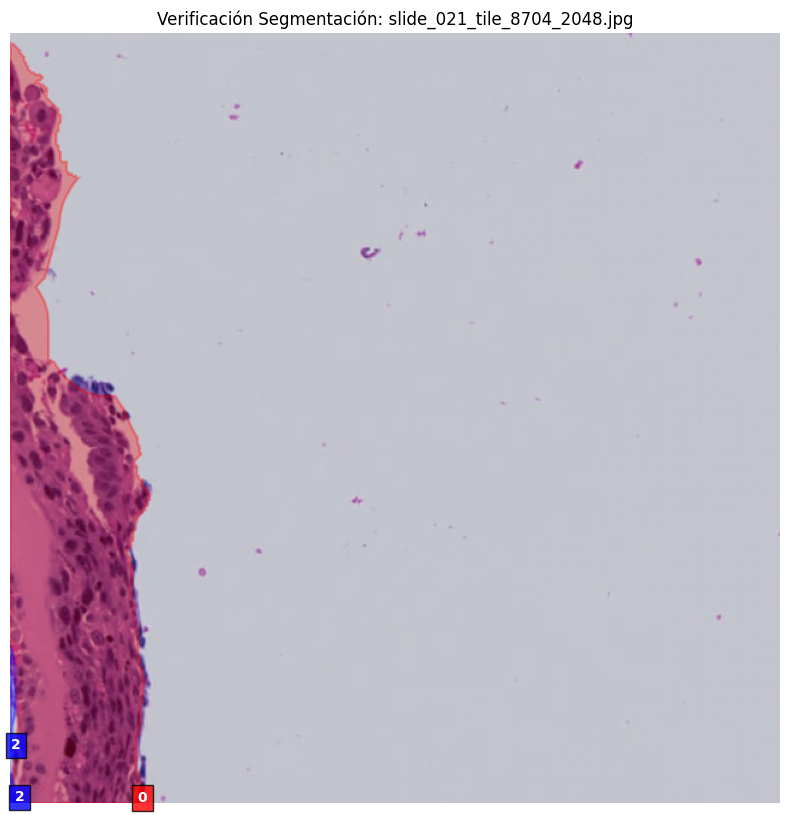

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def verify_yolo_segmentation(img_path, label_path):
    # 1. Cargar la imagen del parche
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w, _ = img.shape
    
    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img)
    
    # 2. Leer el archivo de labels (.txt)
    if os.path.exists(label_path):
        with open(label_path, 'r') as f:
            lines = f.readlines()
            
        for line in lines:
            data = list(map(float, line.split()))
            class_id = int(data[0])
            # Los puntos vienen en pares x, y normalizados
            points = np.array(data[1:]).reshape(-1, 2)
            
            # Desnormalizar puntos para dibujar sobre la imagen de 1024px
            points[:, 0] *= w
            points[:, 1] *= h
            
            # Crear el polígono para visualizar
            # Usamos un color distinto por clase (0: Rojo, 1: Verde, 2: Azul)
            colors = ['red', 'green', 'blue']
            color = colors[class_id] if class_id < len(colors) else 'yellow'
            
            poly_patch = patches.Polygon(points, closed=True, linewidth=2, 
                                         edgecolor=color, facecolor=color, alpha=0.3)
            ax.add_patch(poly_patch)
            ax.text(points[0,0], points[0,1], str(class_id), color='white', 
                    fontweight='bold', bbox=dict(facecolor=color, alpha=0.8))

    plt.title(f"Verificación Segmentación: {os.path.basename(img_path)}")
    plt.axis('off')
    plt.show()

# --- PRUEBA CON UN PARCHE ALEATORIO ---
# Buscamos en la carpeta de train algún archivo generado
sample_images = glob.glob(os.path.join(OUTPUT_DIR, "images/train/*.jpg"))
if sample_images:
    ind = random.randint(0, len(sample_images) - 1)
    test_img = sample_images[ind]
    test_label = test_img.replace("images", "labels").replace(".jpg", ".txt")
    verify_yolo_segmentation(test_img, test_label)
else:
    print("❌ No se encontraron parches. Asegúrate de correr el script de tiling primero.")

# Mover tiles fondo a dataset original

In [6]:
import os
import shutil

# --- CONFIGURACIÓN ---
# La carpeta donde generaste los fondos nuevos
SOURCE_DIR = r"C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs"
# La carpeta de tu dataset original donde están los parches con etiquetas
DEST_DIR = r"C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024"

# --- ESTRUCTURA ---
subfolders = [
    os.path.join("images", "train"),
    os.path.join("images", "val"),
    os.path.join("labels", "train"),
    os.path.join("labels", "val")
]

# --- PROCESO DE MOVIMIENTO ---
for subfolder in subfolders:
    source_path = os.path.join(SOURCE_DIR, subfolder)
    dest_path = os.path.join(DEST_DIR, subfolder)
    
    # Verificar si la carpeta de origen existe
    if os.path.exists(source_path):
        print(f"📂 Moviendo archivos de: {source_path} a {dest_path}")
        
        # Asegurar que la carpeta de destino exista
        os.makedirs(dest_path, exist_ok=True)
        
        # Mover todos los archivos
        files = os.listdir(source_path)
        for file in files:
            #print(file)
            shutil.move(os.path.join(source_path, file), os.path.join(dest_path, file))
        
        print(f"✅ {len(files)} archivos movidos a {subfolder}.")
    else:
        print(f"⚠️ La carpeta de origen no existe: {source_path}")

print("\n🚀 Fusión de datasets completada.")

📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\images\train a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\images\train
✅ 253 archivos movidos a images\train.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\images\val a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\images\val
✅ 56 archivos movidos a images\val.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\labels\train a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\labels\train
✅ 253 archivos movidos a labels\train.
📂 Moviendo archivos de: C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024_bgs\labels\val a C:\Users\paez\Documents\Doct_2026\ratitas_2026\data\processed\yolo_dataset_1024x1024\l

# Nueva generación de tiles 12-02

In [3]:
# tiling_corregido.py
import os
import json
import cv2
import numpy as np
import tifffile
from pathlib import Path
from shapely.geometry import box, shape
from shapely.affinity import translate
from shapely.ops import unary_union

# Configuración
TILE_SIZE = 1280
OVERLAP = 256
STRIDE = TILE_SIZE - OVERLAP

def normalize_class_name(name):
    """Normaliza nombres de clase"""
    mapping = {
        'Decidua': 'Decidua', 'Decidual': 'Decidua', 'dec': 'Decidua', 
        'dec1': 'Decidua', 'dec2': 'Decidua',
        'Junctional Zone': 'Junctional Zone', 'Junctional zone': 'Junctional Zone',
        'Junctional': 'Junctional Zone', 'jz': 'Junctional Zone',
        'jz1': 'Junctional Zone', 'jz2': 'Junctional Zone',
        'Labyrinth': 'Labyrinth', 'Labryinth': 'Labyrinth',
        'lab': 'Labyrinth', 'lab1': 'Labyrinth', 'lab2': 'Labyrinth'
    }
    return mapping.get(name, None)

def get_dominant_class(tile_box, features, min_area_ratio=0.5):
    """
    Determina la clase dominante en un tile.
    Retorna: (clase_dominante, dict_de_areas)
    """
    tile_area = tile_box.area
    class_areas = {}
    
    for feat in features:
        geom = feat['geom']
        if not tile_box.intersects(geom):
            continue
        
        inter = tile_box.intersection(geom)
        if inter.is_empty:
            continue
        
        cls = normalize_class_name(feat['class'])
        if not cls:
            continue
        
        class_areas[cls] = class_areas.get(cls, 0) + inter.area
    
    # Si no hay intersecciones, es Background
    if not class_areas:
        return 'Background', {}
    
    # Encontrar clase dominante
    dominant_cls = max(class_areas, key=class_areas.get)
    dominant_area = class_areas[dominant_cls]
    
    # Si la clase dominante no alcanza el umbral, es Mixed
    if dominant_area / tile_area < min_area_ratio:
        return 'Mixed', class_areas
    
    return dominant_cls, class_areas

def create_stratified_tiles(img_path, geojson_path, output_dir, split, 
                           target_per_class=None):
    """
    Genera tiles estratificados por clase dominante.
    """
    if target_per_class is None:
        target_per_class = {
            'Decidua': 80,
            'Junctional Zone': 80, 
            'Labyrinth': 60,
            'Background': 40
        }
    
    base_name = Path(img_path).stem
    
    # Cargar imagen
    with tifffile.TiffFile(img_path) as tif:
        page = tif.pages[0]
        full_img = page.asarray()
        if len(full_img.shape) == 2:
            full_img = cv2.cvtColor(full_img, cv2.COLOR_GRAY2BGR)
        elif full_img.shape[2] == 4:
            full_img = cv2.cvtColor(full_img, cv2.COLOR_RGBA2BGR)
        else:
            full_img = cv2.cvtColor(full_img, cv2.COLOR_RGB2BGR)
    
    h, w = full_img.shape[:2]
    
    # Cargar y normalizar anotaciones
    with open(geojson_path, 'r') as f:
        data = json.load(f)
    
    features = []
    for f in data.get('features', []):
        cls = normalize_class_name(f['properties'].get('name'))
        if cls:
            features.append({
                'geom': shape(f['geometry']),
                'class': cls
            })
    
    # Generar todos los tiles y clasificarlos
    tiles_by_class = {cls: [] for cls in list(target_per_class.keys()) + ['Mixed']}
    
    print(f"  Generando grid...")
    
    for y in range(0, h - TILE_SIZE + 1, STRIDE):
        for x in range(0, w - TILE_SIZE + 1, STRIDE):
            tile_box = box(x, y, x + TILE_SIZE, y + TILE_SIZE)
            
            # Obtener clase dominante y áreas
            dominant_cls, areas_dict = get_dominant_class(tile_box, features, min_area_ratio=0.5)
            
            tile_info = {
                'x': x, 
                'y': y,
                'dominant_class': dominant_cls,
                'areas': areas_dict,  # Siempre es un diccionario
                'box': tile_box
            }
            
            # Guardar en la lista correspondiente
            if dominant_cls in tiles_by_class:
                tiles_by_class[dominant_cls].append(tile_info)
            else:
                tiles_by_class['Mixed'].append(tile_info)
    
    # Seleccionar tiles estratificados
    selected_tiles = []
    
    for cls, target_count in target_per_class.items():
        available = tiles_by_class.get(cls, [])
        
        if len(available) == 0:
            print(f"    ⚠️  No hay tiles de {cls}")
            continue
        
        # Seleccionar los mejores
        if cls == 'Background':
            # Menor contaminación de tejido
            scored = []
            for t in available:
                # Sumar todas las áreas de clases (t['areas'] es dict)
                total_annotated = sum(t['areas'].values())
                scored.append((t, total_annotated))
            
            scored.sort(key=lambda x: x[1])  # Menor área anotada primero
            selected = [t[0] for t in scored[:target_count]]
            
        else:
            # Mayor área de la clase objetivo
            scored = []
            for t in available:
                area_cls = t['areas'].get(cls, 0)
                scored.append((t, area_cls))
            
            scored.sort(key=lambda x: x[1], reverse=True)
            selected = [t[0] for t in scored[:target_count]]
        
        selected_tiles.extend(selected)
        print(f"    {cls}: {len(selected)}/{len(available)}")
    
    # Incluir algunos mixtos
    mixed = tiles_by_class.get('Mixed', [])
    if len(mixed) > 0:
        n_mixed = min(20, len(mixed))
        selected_tiles.extend(mixed[:n_mixed])
        print(f"    Mixed: {n_mixed}/{len(mixed)}")
    
    # Guardar tiles
    count = 0
    for tile in selected_tiles:
        x, y = tile['x'], tile['y']
        
        tile_img = full_img[y:y+TILE_SIZE, x:x+TILE_SIZE]
        tile_box = tile['box']
        
        # Generar etiquetas YOLO
        labels = []
        
        for feat in features:
            if not tile_box.intersects(feat['geom']):
                continue
            
            inter = tile_box.intersection(feat['geom'])
            if inter.is_empty or inter.area < 100:
                continue
            
            local_poly = translate(inter, xoff=-x, yoff=-y)
            
            cls_name = normalize_class_name(feat['class'])
            class_id = {'Decidua': 0, 'Junctional Zone': 1, 'Labyrinth': 2}.get(cls_name)
            
            if class_id is not None:
                # Convertir a segmento YOLO
                if hasattr(local_poly, 'exterior'):
                    coords = np.array(local_poly.exterior.coords)
                    coords_norm = coords / TILE_SIZE
                    coords_norm = np.clip(coords_norm, 0, 1)
                    
                    flat = coords_norm.flatten()[:30]
                    coord_str = ' '.join([f"{c:.6f}" for c in flat])
                    labels.append(f"{class_id} {coord_str}")
        
        # Guardar
        tile_name = f"{base_name}_x{x}_y{y}_{tile['dominant_class']}"
        img_path_out = Path(output_dir) / "images" / split / f"{tile_name}.jpg"
        lbl_path_out = Path(output_dir) / "labels" / split / f"{tile_name}.txt"
        
        img_path_out.parent.mkdir(parents=True, exist_ok=True)
        lbl_path_out.parent.mkdir(parents=True, exist_ok=True)
        
        cv2.imwrite(str(img_path_out), tile_img)
        
        with open(lbl_path_out, 'w') as f:
            f.write('\n'.join(labels))
        
        count += 1
    
    return count




In [4]:
IMAGE_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/wsi_images"
ANNOTATIONS_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/raw/annotations_resized"
OUTPUT_DIR = "/media/lci1/fac1e379-9201-42aa-80e8-b6775b0ab41b/JA/ratitas_2026/data/processed/YOLO-stratified-1280-256ovlp"

all_images = list(Path(IMAGE_DIR).glob("*.tif"))
np.random.seed(42)
np.random.shuffle(all_images)

split_idx = int(len(all_images) * 0.8)
train_files = set(str(p) for p in all_images[:split_idx])

total_tiles = 0

for img_path in all_images:
    base_name = img_path.stem
    geojson_path = Path(ANNOTATIONS_DIR) / f"{base_name}.geojson"
    
    if not geojson_path.exists():
        continue
    
    split = "train" if str(img_path) in train_files else "val"
    print(f"\n🚜 {base_name} → {split}")
    
    count = create_stratified_tiles(
        str(img_path), 
        str(geojson_path), 
        OUTPUT_DIR, 
        split
    )
    total_tiles += count

print(f"\n✅ Total tiles: {total_tiles}")


🚜 slide_043 → train


  Generando grid...
    ⚠️  No hay tiles de Decidua
    ⚠️  No hay tiles de Junctional Zone
    Labyrinth: 12/12
    Background: 10/10
    Mixed: 18/18

🚜 slide_038 → train
  Generando grid...
    ⚠️  No hay tiles de Decidua
    ⚠️  No hay tiles de Junctional Zone
    Labyrinth: 6/6
    ⚠️  No hay tiles de Background
    Mixed: 10/10

🚜 slide_037 → train
  Generando grid...
    ⚠️  No hay tiles de Decidua
    ⚠️  No hay tiles de Junctional Zone
    Labyrinth: 8/8
    Background: 19/19
    Mixed: 18/18

🚜 slide_058 → train
  Generando grid...
    Decidua: 2/2
    Junctional Zone: 17/17
    Labyrinth: 21/21
    Background: 40/55
    Mixed: 20/40

🚜 slide_025 → train
  Generando grid...
    ⚠️  No hay tiles de Decidua
    ⚠️  No hay tiles de Junctional Zone
    Labyrinth: 7/7
    Background: 40/113
    Mixed: 20/23

🚜 slide_044 → train
  Generando grid...
    Decidua: 1/1
    ⚠️  No hay tiles de Junctional Zone
    Labyrinth: 10/10
    Background: 7/7
    Mixed: 10/10

🚜 slide_024 → train